09 : Build an XGBoost classification model to predict whether a customer will take the travel package
(ProdTaken) using demographic and marketing features. The process includes handling missing values (e.g.,
Age, Income, DurationOfPitch), encoding categorical variables (Occupation, Gender, TypeofContact, etc.),
feature engineering, and balancing class distribution. The model will be trained and evaluated using AUCROC and F1 score to ensure robust prediction of customer decisions.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier 
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix, classification_report, roc_curve, RocCurveDisplay
from sklearn.impute import SimpleImputer

In [4]:
df = pd.read_csv('Travel.csv')
print("Dataset Shape :", df.shape)
df.head()

Dataset Shape : (4888, 20)


,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [5]:
if df.isnull().sum().sum() > 0:
    print("Missing Values Present !!")
    print(df.isnull().sum())
else :
    print("No Missing Values Found")

Missing Values Present !!
CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64


In [6]:
df.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting',
       'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar',
       'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore',
       'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='object')

In [10]:
x = df.dropna(subset=['ProdTaken']).copy()
x = df.drop(
    columns=['ProdTaken', 'CustomerID'],
    errors='ignore'
)

y = df['ProdTaken'].astype(int)

print("Feature Shape:", x.shape)
print("Target Shape:", y.shape)
print("\nTarget Distribution:")
print(y.value_counts())

Feature Shape: (4888, 18)
Target Shape: (4888,)

Target Distribution:
ProdTaken
0    3968
1     920
Name: count, dtype: int64


In [12]:
num_cols = x.select_dtypes(include=np.number).columns.tolist()
cat_cols = x.select_dtypes(include=['object', 'bool', 'category']).columns.tolist()

print("Numerical Features:", num_cols)
print("Categorical Features:", cat_cols)

Numerical Features: ['Age', 'CityTier', 'DurationOfPitch', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'PreferredPropertyStar', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting', 'MonthlyIncome']
Categorical Features: ['TypeofContact', 'Occupation', 'Gender', 'ProductPitched', 'MaritalStatus', 'Designation']


In [15]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (3910, 18)
Testing data: (978, 18)


In [18]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy='mean'))
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("encoder", OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

In [19]:
negative_count = (y_train==0).sum()
positive_count = (y_train==1).sum()

scale_pos_weight = negative_count / max(positive_count, 1)

print("Non-Purchase Customers:", negative_count)
print("Purchase Customers:", positive_count)
print("Scale Positive Weight:", round(scale_pos_weight, 2))

Non-Purchase Customers: 3174
Purchase Customers: 736
Scale Positive Weight: 4.31


In [21]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(x_train, y_train)
print("XGBoost Model Training Completed")

XGBoost Model Training Completed


In [23]:
y_pred = model.predict(x_test)
y_prob = model.predict_proba(x_test)[:, 1]

print("Predictions:")
print(y_pred[:10])

print("\nPurchase Probabilities:")
print(np.round(y_prob[:10], 3))

Predictions:
[1 0 1 1 0 0 0 0 0 0]

Purchase Probabilities:
[0.767 0.14  0.928 0.713 0.199 0.143 0.316 0.182 0.277 0.315]


In [24]:
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("XGBOOST CLASSIFICATION RESULTS")
print("Accuracy :", round(accuracy, 4))
print("AUC-ROC  :", round(auc, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

XGBOOST CLASSIFICATION RESULTS
Accuracy : 0.8016
AUC-ROC  : 0.8374
F1 Score : 0.5509

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.84      0.87       794
           1       0.48      0.65      0.55       184

    accuracy                           0.80       978
   macro avg       0.70      0.74      0.71       978
weighted avg       0.83      0.80      0.81       978



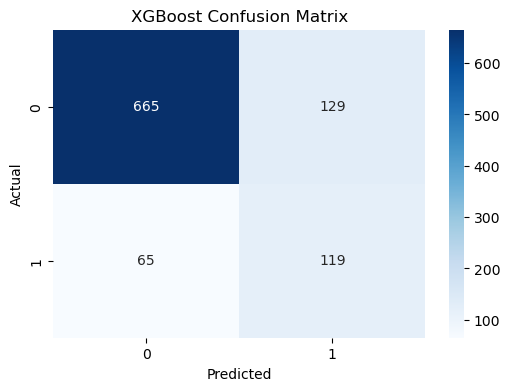

In [25]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

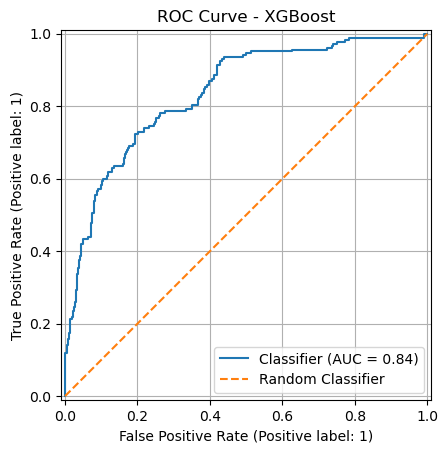

In [28]:
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
comparison = pd.DataFrame({
    "Actual ProdTaken": y_test.to_numpy(),
    "Predicted ProdTaken": y_pred,
    "Purchase Probability": y_prob
}, index=x_test.index)

print("ACTUAL VS PREDICTED VALUES")
print(comparison.head(10))

ACTUAL VS PREDICTED VALUES
      Actual ProdTaken  Predicted ProdTaken  Purchase Probability
3006                 1                    1              0.766670
773                  0                    0              0.140071
4623                 1                    1              0.928475
3787                 0                    1              0.713262
576                  0                    0              0.199303
1374                 0                    0              0.142657
1455                 0                    0              0.316221
2027                 0                    0              0.182117
1525                 0                    0              0.276702
236                  1                    0              0.314806


In [31]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "AUC-ROC", "F1 Score"],
    "XGBoost": [accuracy, auc, f1]
})

print("MODEL PERFORMANCE")
print(results.to_string(index=False))

MODEL PERFORMANCE
  Metric  XGBoost
Accuracy 0.801636
 AUC-ROC 0.837374
F1 Score 0.550926
